# Tomato leaf classification with a CNN

This notebook accompanies the actually trained PlantVillage experiment. It adapts Tutorial 5's workflow: compare two configurations with five-fold cross-validation, retrain the selected configuration, then evaluate it once on a separate test set.

Open this notebook alongside `train.py`, `download_data.py`, and the `outputs` directory. Choose the project Python environment. The completed experiment can be explored on CPU. Training needs an NVIDIA GPU.


In [1]:
from pathlib import Path
import json
import sys
import torch

ROOT = Path.cwd()
if not (ROOT / "train.py").exists():
    ROOT = ROOT / "plant_tomato"
sys.path.insert(0, str(ROOT))
from train import TomatoCNN, CONFIGS
OUT = ROOT / "outputs"
print("Python:", sys.version)
print("CUDA available:", torch.cuda.is_available())


Python: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
CUDA available: True


## Data and independent evaluation

Only original tomato RGB images are used. Exact duplicates and known images of the same leaf stay together. The development set contains 14,528 images; the test set contains 3,632. Known leaf metadata is incomplete, so the report gives its coverage and the grouping limitations.

Augmentation and inverse-frequency loss weights use training-fold data. The fixed preprocessing uses no fitted statistics from the test set. Selection uses mean final-epoch macro F1 across five development folds. The final model is retrained from scratch on the complete development set.


In [2]:
experiment = json.loads((OUT / "experiment.json").read_text())
print(json.dumps(experiment, indent=2))


{
  "dataset": "Original PlantVillage tomato RGB images",
  "classes": [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy"
  ],
  "images": 18160,
  "development_images": 14528,
  "test_images": 3632,
  "unique_groups": 9589,
  "mapped_images": 11411,
  "unique_byte_hashes": 18146,
  "unique_pixel_hashes": 18146,
  "class_counts": {
    "Tomato___Bacterial_spot": {
      "total": 2127,
      "development": 1700,
      "test": 427
    },
    "Tomato___Early_blight": {
      "total": 1000,
      "development": 800,
      "test": 200
    },
    "Tomato___Late_blight": {
      "total": 1909,
      "development": 1527,
      "test": 382
    },
    "Tomato___Leaf_Mold": {
      "total": 952,
      "development":

## Two CNN configurations

Each block has two 3x3 convolutions, batch normalization, ReLU, and max pooling. The classifier uses adaptive pooling, 128 dense units, dropout, and ten output logits. Models are trained from scratch.


In [3]:
for name, channels in CONFIGS.items():
    model = TomatoCNN(channels)
    print(name, "channels:", channels, "parameters:", sum(p.numel() for p in model.parameters()))
print(model)


compact channels: (16, 32, 64) parameters: 106490
deeper channels: (32, 64, 128, 192) parameters: 940906
TomatoCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runni

## Cross-validation results

Both configurations use the same grouped folds, batch size, augmentation, optimizer, and fixed 20-epoch budget. Accuracy alone can obscure weak minority-class performance. Macro F1 gives each of the ten classes equal importance.


In [4]:
cv = json.loads((OUT / "cross_validation.json").read_text())
for name, scores in cv.items():
    print(f"{name}: accuracy={scores['mean_accuracy']:.4f} +/- {scores['sd_accuracy']:.4f}; macro F1={scores['mean_macro_f1']:.4f} +/- {scores['sd_macro_f1']:.4f}")


compact: accuracy=0.9528 +/- 0.0060; macro F1=0.9404 +/- 0.0088
deeper: accuracy=0.9756 +/- 0.0029; macro F1=0.9704 +/- 0.0031


## Final held-out results

Accuracy is the fraction of correct classifications. Precision is TP/(TP+FP); recall is TP/(TP+FN); F1 is 2PR/(P+R). Macro metrics average over classes equally; weighted F1 weights by class support. The confidence intervals resample complete leaf/duplicate groups.

These are measured PlantVillage results, not evidence of performance on farms or field photographs. The secondary unhealthy-versus-healthy task includes spider-mite damage as unhealthy.


In [5]:
metrics = json.loads((OUT / "test_metrics.json").read_text())
for key in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "macro_roc_auc_ovr"]:
    print(f"{key}: {metrics[key]:.6f}")
for name, values in metrics["per_class"].items():
    if name.startswith("Tomato___"):
        print(name, "precision", round(values["precision"], 4), "recall", round(values["recall"], 4), "F1", round(values["f1-score"], 4), "support", int(values["support"]))


accuracy: 0.984581
macro_precision: 0.980862
macro_recall: 0.983789
macro_f1: 0.982308
weighted_f1: 0.984606
macro_roc_auc_ovr: 0.999760
Tomato___Bacterial_spot precision 0.9744 recall 0.9789 F1 0.9766 support 427
Tomato___Early_blight precision 0.9552 recall 0.96 F1 0.9576 support 200
Tomato___Late_blight precision 0.9818 recall 0.9895 F1 0.9857 support 382
Tomato___Leaf_Mold precision 0.9894 recall 0.9894 F1 0.9894 support 188
Tomato___Septoria_leaf_spot precision 0.9858 recall 0.9802 F1 0.983 support 354
Tomato___Spider_mites Two-spotted_spider_mite precision 0.9649 recall 0.9821 F1 0.9735 support 336
Tomato___Target_Spot precision 0.9714 recall 0.968 F1 0.9697 support 281
Tomato___Tomato_Yellow_Leaf_Curl_Virus precision 0.9991 recall 0.9897 F1 0.9944 support 1072
Tomato___Tomato_mosaic_virus precision 0.9867 recall 1.0 F1 0.9933 support 74
Tomato___healthy precision 1.0 recall 1.0 F1 1.0 support 318


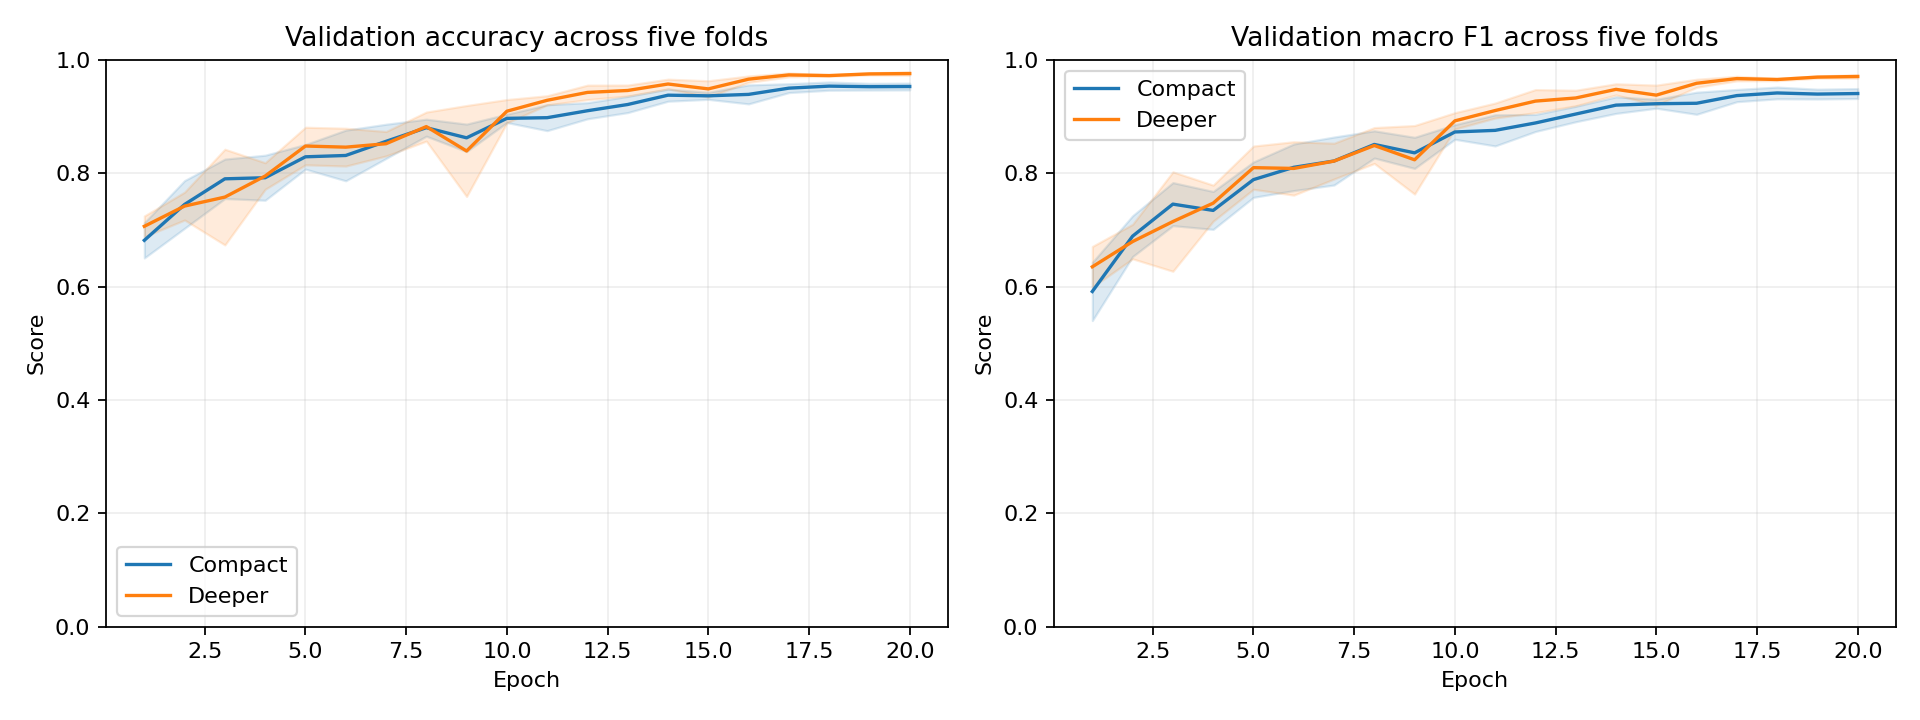

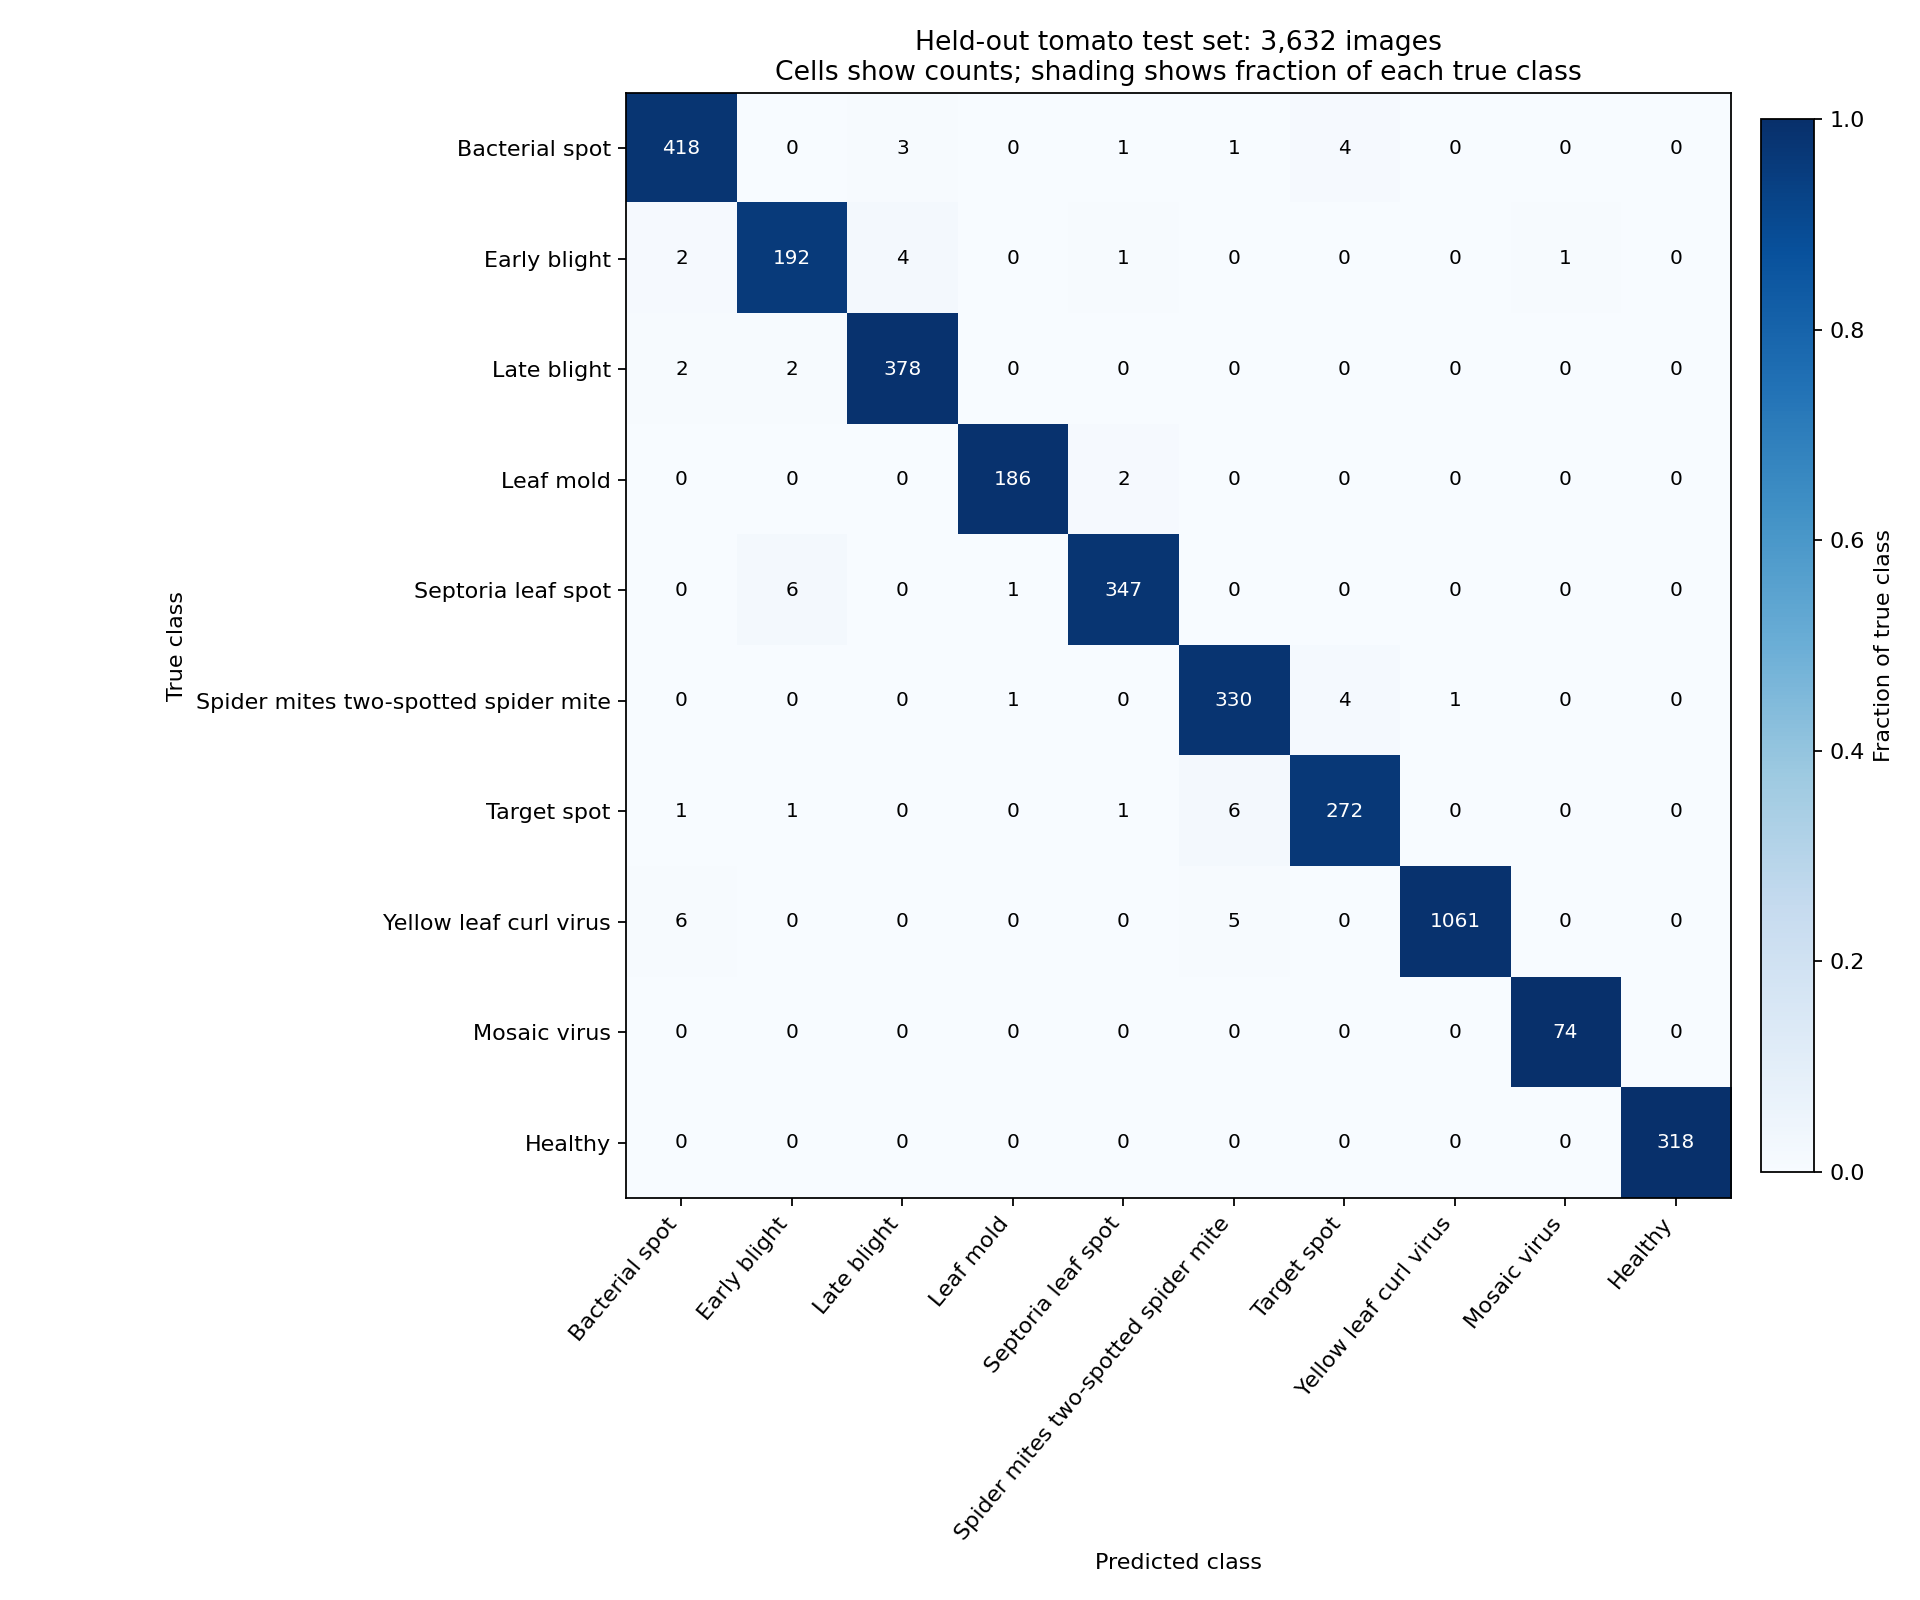

In [6]:
from IPython.display import Image, display
display(Image(filename=str(OUT / "cross_validation_curves.png")))
display(Image(filename=str(OUT / "confusion_matrix.png")))


## Verify the experiment

The audit checks group/hash separation and independently recomputes scores from saved confusion counts. This does not rerun inference on the test set.


In [7]:
import subprocess
subprocess.run([sys.executable, str(ROOT / "verify_results.py")], check=True)


CompletedProcess(args=['C:\\Users\\Nebula PC\\AppData\\Local\\Programs\\Python\\Python314\\python.exe', 'C:\\Users\\Nebula PC\\OneDrive\\Desktop\\Usyd\\plant_tomato\\verify_results.py'], returncode=0)

## Optional fresh training

Leave `RUN_FRESH_TRAINING` false to explore the completed experiment. For a new experiment, use a separate folder without completed test metrics. Do not repeatedly tune settings against the completed test results.


In [8]:
RUN_FRESH_TRAINING = False
if RUN_FRESH_TRAINING:
    assert not (OUT / "test_metrics.json").exists(), "Use a separate fresh experiment folder."
    assert torch.cuda.is_available(), "Training requires an NVIDIA GPU."
    subprocess.run([sys.executable, str(ROOT / "download_data.py")], check=True)
    subprocess.run([sys.executable, str(ROOT / "train.py"), "--epochs", "20", "--batch-size", "128", "--image-size", "96"], check=True)
    subprocess.run([sys.executable, str(ROOT / "verify_results.py")], check=True)
    subprocess.run([sys.executable, str(ROOT / "make_report.py")], check=True)
